In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.stats import skew

import readgadget
import readfof
import MAS_library as MASL
import smoothing_library as SL
import void_library as VL
import scipy.fft as sfft

512


Text(0.5, 1.0, 'density distribution')

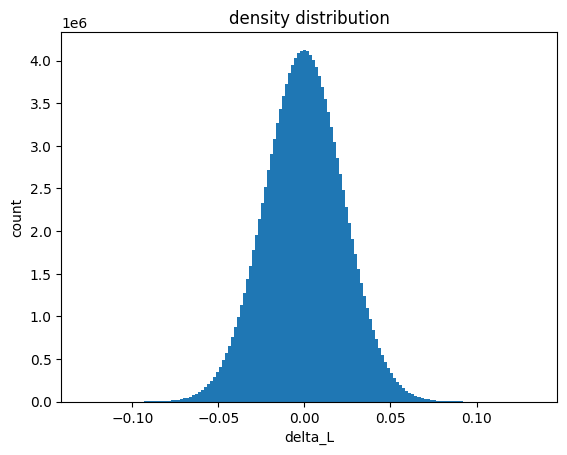

In [2]:
#extract raw fullbox data: box size, particle count, particle IDs, linear density + sorting

#Snaps:
snap_init = "./ICs_Quijote/ics"
snap_fin = "./snaps/snap_003"

box_size = readgadget.header(snap_init).boxsize #kpc/h
ptype = [1]

#Initial snapshot:z=127
all_init_ids = readgadget.read_block(snap_init, "ID  ", ptype)
all_init_pos = readgadget.read_block(snap_init, "POS ", ptype) #kpc/h

#Final snapshot:z=0.5
all_fin_ids = readgadget.read_block(snap_fin, "ID  ", ptype)
all_fin_pos = readgadget.read_block(snap_fin, "POS ", ptype) #kpc/h

#------------------------------------------------------------
#Sort and organize data as necessary

#Sorter for final snapshot
sort_order_fin = np.argsort(all_fin_ids) 
fin_pos_sorted = all_fin_pos[sort_order_fin] # np.argsort returns indices that would sort an array
# the above is basically: fin_pos_sorted = all_fin_pos[np.argsort(all_fin_ids)], now in this file storage
# system, the IDs are not stored sorted, they are stored per which processor they were on - so this step
# is necessary, now we have the final positions sorted according to their particle IDs as a one-one 
# correspondence exists between the IDs file and the POS file.
# tl:dr: this ensures position is sorted by ID

#Sorter for ICs
sort_order_init = np.argsort(all_init_ids)
init_ids_sorted = all_init_ids[sort_order_init]
init_pos_sorted = all_init_pos[sort_order_init]

#sanity check if the sorted init IDs actually has all the IDs sorted
N = 512
assert np.array_equal(init_ids_sorted, np.arange(1, N**3 + 1)), "IDs are not a permutation of 1..N"

#------------------------------------------------------------
#Loading IC lin density field
delta_L = np.load("linICfield.npy")
delta_L_flat = delta_L.flatten()
print(len(delta_L)) #sanity check

#Checking density distribution: histogram
plt.hist(delta_L_flat, bins = 150)
plt.xlabel("delta_L")
plt.ylabel("count")
plt.title("density distribution")


In [3]:
#extract halo centers (with FoF) (at z=0.5)

#specifying details needed for fof reading
redshift = 0.5
snapdir = "./"
snapnum = 3

FoF = readfof.FoF_catalog(snapdir, snapnum, long_ids=False, swap=False, SFR=False, read_IDs=True) #keep read_IDs true to identify which particles fall in which halos!

halo_sizes = FoF.GroupLen
halo_ids = FoF.GroupIDs
halo_centers = FoF.GroupPos 
# going to keep it at this for now, will make a dict if halo extent is needed later on, not needed for this purpose I think

In [4]:
#extract void centers (at z=0.5)

#this uses Pylians void_library as such some unit conversions are necessary. such as lengths are stored in kpc/h in these snapshots but Pylians uses and expects Mpc/h
BoxSize = box_size/1e3 #now in Mpc/h
dims = N
pos =fin_pos_sorted/1e3 #now in Mpc/h

#this method needs to construct the (number) density field to find voids at the final snapshot
delta = np.zeros((dims,dims,dims), dtype=np.float32)
MASL.MA(pos,delta, BoxSize, 'CIC')
delta /= np.mean(delta, dtype=np.float64)
delta -= 1.0

#these are void finder parameters:
threshold = -0.7
cell_size = BoxSize/dims
Rmin = 3*cell_size #what is the smallest sized void this will accept? here 3 times 1 cell
Rmax = BoxSize/2.0
bins = 30 # this is the number of scales between Rmin and Rmax it smooths at per while scanning
Radii = np.logspace(np.log10(Rmin), np.log10(Rmax), bins+1, dtype = np.float32)
threads1 = 8
threads2 = 4

#Void finding
V= VL.void_finder(delta, BoxSize, threshold, Radii, threads1, threads2, void_field=True)

#Storing void data
void_centers = V.void_pos * 1e3 #converting units back to kpc
print(len(void_centers), "voids")


maximum number of voids = 1186745

Smoothing field with top-hat filter of radius 500.00
Density smoothing took 4.162 seconds
No cells with delta < -0.70

Smoothing field with top-hat filter of radius 431.12
Density smoothing took 3.220 seconds
No cells with delta < -0.70

Smoothing field with top-hat filter of radius 371.73
Density smoothing took 3.206 seconds
No cells with delta < -0.70

Smoothing field with top-hat filter of radius 320.52
Density smoothing took 2.791 seconds
No cells with delta < -0.70

Smoothing field with top-hat filter of radius 276.37
Density smoothing took 2.694 seconds
No cells with delta < -0.70

Smoothing field with top-hat filter of radius 238.30
Density smoothing took 2.714 seconds
No cells with delta < -0.70

Smoothing field with top-hat filter of radius 205.47
Density smoothing took 2.634 seconds
No cells with delta < -0.70

Smoothing field with top-hat filter of radius 177.16
Density smoothing took 2.649 seconds
No cells with delta < -0.70

Smoothing fie

In [5]:
#deposit delta_L onto particles i.e. positions (NGP)

#NGP readout, using this for now
def ngp_readout(field, pos, L, chunk = 1<<24):
    "field: (N,N,N) array indexed by [x,y,z]; pos: (Np,3) array - position of each particle, in the same "
    "units as L"
    N = field.shape[0] #length of one side of field arraay -0th
    ff = field.ravel()
    s = N/L # inverse length of 1 cell
    out = np.empty(len(pos),dtype = field.dtype)

    for a in range (0, len(pos), chunk):
        p = pos[a:a+chunk]
        ix = (p[:,0]*s+0.5).astype(np.int64)
        iy = (p[:,1]*s+0.5).astype(np.int64)
        iz = (p[:,2]*s+0.5).astype(np.int64)

        ix %= N; iy %= N; iz%=N

        flat_idx = ix * (N*N)
        flat_idx += iy*N
        flat_idx += iz

        out[a:a+chunk] = ff.take(flat_idx)

    return out

delta_L_p = ngp_readout(delta_L, init_pos_sorted, box_size)

In [6]:
#variance in radius shells, cumulative

#replacement for _sorted_sphere and the bias/var_vs_radius functions, now it bins. should be faster 

def var_vs_radius_binned(pos, vals, centre, radii, L):
    radii = np.asarray(radii, dtype=np.float64)
    R_max = radii.max() #this part sets up the radius list and the largest radius, for filtering out other points
    if R_max >= L / 2:
        raise ValueError("radius must be < L/2") #this is so the sphere doesn't overlap it's periodic image

    # in sphere selection
    dx = pos[:, 0] - centre[0] #distance from passed center
    dx -= L * np.rint(dx / L) #periodic wrapping : minimum image convention
    cand = np.flatnonzero(np.abs(dx) < 1.001 * R_max) #candidate, only considers particles in sphere of largest radius centered at current center
    #cand applies a cheap prefilter, only particles which are less that Rmax/2 away from center along X are inside the sphere so full distance is computed for those only
    d = pos[cand].astype(np.float64) - np.asarray(centre, dtype=np.float64) #distances from center of candidate particles
    d -= L * np.rint(d / L) #periodic wrapping
    r = np.sqrt((d * d).sum(axis=1)) #full 3d distance to each candidate
    keep = r < R_max #keeps only those particles that are inside Rmax sphere
    r = r[keep] #radius of kept particles
    v = vals[cand[keep]].astype(np.float64) #field values at positions inside largest sphere are stored

    # binning: which shell does each particle fall in?
    shell = np.searchsorted(radii, r, side="left")   # 0 .. len(radii)-1 # this gives each particle the index of the SMALLEST radius that can contain it
    K = len(radii) #no. of radii passed to the function

    w = v - v.mean()#this centers the delta values, avouds cancellation error
    n_shell  = np.bincount(shell, minlength=K)#number of particles in a particular radius shell (between two consequetive radii)
    s1_shell = np.bincount(shell, weights=w,     minlength=K)#sum of centerred delta ina shell
    s2_shell = np.bincount(shell, weights=w * w, minlength=K)#sum of square of delta in a shell
    #the above come from np.bincount which takes the radii indices and total number of radii and divides that into bins between consequetive radii

    # running totals = everything inside each radius
    n  = np.cumsum(n_shell) #cumulative sums ensure all particles inside each radius are considered
    c1 = np.cumsum(s1_shell)
    c2 = np.cumsum(s2_shell)
    #same as s but cumulative instead

    n_safe = np.maximum(n, 1)#to avoid division by 0
    var = c2 / n_safe - (c1 / n_safe) ** 2 #variance identity
    var[n == 0] = np.nan #so no particles isn't mistaken for 0 variance
    return dict(var=var, n=n, radii=radii) #the function returns a dictionary with keys var, n and radii, each with as many entries as radii passed

In [7]:
#sorting halos by massiveness

halo_mass = FoF.GroupMass

mass_order = np.argsort(halo_sizes)[::-1]
halo_centers_sorted = halo_centers[mass_order]
halo_sizes_sorted = halo_sizes[mass_order]

void_radius  = V.void_radius       # (Nvoids,), Mpc/h

order = np.argsort(void_radius, kind="stable")[::-1]     # largest first
void_centers_sorted = void_centers[order]
void_radius_sorted  = void_radius[order]

In [ ]:
#claude solution for running through bins without crashing?

def build_cells(pos, vals, L, ncell, chunk=1<<24):
    cs = L / ncell
    cid = np.empty(len(pos), dtype=np.int32)
    for a in range(0, len(pos), chunk):
        c = (pos[a:a+chunk] / cs).astype(np.int64) % ncell
        cid[a:a+chunk] = (c[:, 0] * ncell + c[:, 1]) * ncell + c[:, 2]
    order = np.argsort(cid, kind="stable")
    counts = np.bincount(cid, minlength=ncell**3)
    start = np.concatenate([[0], np.cumsum(counts)])
    return pos[order], vals[order], start, cs, ncell

#this bit of code is supposed 

def local_subset(centre, R_max, cells):
    pos_s, vals_s, start, cs, ncell = cells
    k = int(np.ceil(R_max / cs))
    c0 = (np.asarray(centre) / cs).astype(int)
    r = np.arange(-k, k + 1)
    ix, iy, iz = (c0[0] + r) % ncell, (c0[1] + r) % ncell, (c0[2] + r) % ncell
    ids = np.unique((ix[:, None, None] * ncell + iy[None, :, None]) * ncell + iz[None, None, :])
    sl = [slice(start[i], start[i + 1]) for i in ids]
    return (np.concatenate([pos_s[s] for s in sl]),
            np.concatenate([vals_s[s] for s in sl]))


In [27]:
#SAMPLING CENTERS (using the cell above)

radii_30 = np.logspace(3, 5, 30)
#random centers at z=127
cells = build_cells(init_pos_sorted, delta_L_p, box_size, ncell=40)      # ~25 Mpc/h cells for L=1000
#del init_pos_sorted, delta_L_p                                    # free the originals

out = []

#generating random centers
rng = np.random.default_rng(42)          # seed for reproducibility
L = 1000000.0                               # in kpc/h, = 1000 MPpc/h
centers = rng.uniform(0, L, size=(10000, 3)) #NO. OF CENTERS IS HERE

for c in centers:
    p, v = local_subset(c, radii_30.max(), cells)
    out.append(var_vs_radius_binned(p, v, c, radii_30, L))
#sampling random centers at z=0.5

cells_fin = build_cells(fin_pos_sorted, delta_L_p, box_size, ncell=40)      # ~25 Mpc/h cells for L=1000
#del init_pos_sorted, delta_L_p                                    # free the originals

out_fin = []

#will use the same set of centers as IC sample
for c in centers:
    p, v = local_subset(c, radii_30.max(), cells_fin)
    out_fin.append(var_vs_radius_binned(p, v, c, radii_30, L))

KeyboardInterrupt: 

In [ ]:

import time


# parameters to use
L          = box_size                         # 1e6 kpc/h                          
VOID_IN_MPC = False                            # True if void_centres_sorted came straight from Pylians (Mpc/h)
#False here because we reconverted to kpc
N_RAND = 10_000                           # No. of random lagrangian points to sample
#N_RAND_EUL = 3_000                            # Eulerian baseline
var_g = np.var(delta_L_p, dtype=np.float64)   # global variance of the linear field

def run_centres(centres, cells, label):
    "wraps the loop from the previous cell, times the run and collects only one result per center. Then it prints a summary of variance and count"
    t0 = time.time(); res = []
    for c in centres:
        p, v = local_subset(c, radii_30.max(), cells)
        res.append(var_vs_radius_binned(p, v, c, radii_30, L))
    print(f"{label}: {len(centres)} centres, {time.time()-t0:.0f}s")
    return (np.array([r["var"] for r in res]), np.array([r["n"] for r in res]))

# random baseline (initial positions) 
# reuse out if matches:
if "out" in globals() and len(out) == N_RAND and np.allclose(out[0]["radii"], radii_30):
    var_rl = np.array([o["var"] for o in out]); n_rl = np.array([o["n"] for o in out])
    print("reusing existing `out`")
else:
    cells = build_cells(init_pos_sorted, delta_L_p, L, ncell=40)
    rng = np.random.default_rng(42)
    centres_rl = rng.uniform(0, L, size=(N_RAND, 3))
    var_rl, n_rl = run_centres(centres_rl, cells, "random, z=127")
    del cells
np.savez("var_random_lagrangian.npz", radii=radii_30, var=var_rl, n=n_rl)


halo_raw = np.asarray(halo_centers_sorted[:10000])
void_raw = np.asarray(void_centers_sorted[:10000])      # already kpc/h
assert halo_raw.max() <= 1.001 * L and void_raw.max() <= 1.001 * L, "coordinates not in kpc/h"
halo_pts, void_pts = halo_raw % L, void_raw % L

var_h, n_h = run_centres(halo_pts, cells_fin, "halos, Eulerian")
var_v, n_v = run_centres(void_pts, cells_fin, "voids, Eulerian")
np.savez("var_halos_voids_eulerian.npz", radii=radii_30, var_h=var_h, n_h=n_h, var_v=var_v, n_v=n_v)


reusing existing `out`
halos, Eulerian: 10000 centres, 2049s
voids, Eulerian: 10000 centres, 1746s


In [ ]:
if "out_fin" in globals() and len(out_fin) == N_RAND and np.allclose(out_fin[0]["radii"], radii_30):
    var_fin = np.array([o["var"] for o in out_fin]); n_fin = np.array([o["n"] for o in out_fin])
    print("reusing existing `out`")
else:
    cells = build_cells(fin_pos_sorted, delta_L_p, L, ncell=40)
    rng = np.random.default_rng(42)
    centres_rl = rng.uniform(0, L, size=(N_RAND, 3))
    var_fin, n_fin = run_centres(centres_rl, cells, "random, z=0.5")
    del cells
np.savez("var_random_final.npz", radii=radii_30, var=var_fin, n=n_fin)

# final positions
if "cells" in globals(): del cells                              # free ~2 GB before the next build
cells_fin = build_cells(fin_pos_sorted, delta_L_p, L, ncell=40)


reusing existing `out`


In [ ]:
var_ran_lag_dict = np.load("var_random_lagrangian.npz")
var_halos_voids_dict = np.load("var_halos_voids_eulerian.npz")
var_ran_eul_dict = np.load("var_random_eulerian.npz")

var_rl = var_ran_lag_dict["var_rl"]
var_h = var_halos_voids_dict["var_h"]
var_v = var_halos_voids_dict["var_h"]
var_fin = var_ran_eul_dict["var_re"]

n_rl = var_ran_lag_dict["n_rl"]
n_h = var_halos_voids_dict["n_h"]
n_v = var_halos_voids_dict["n_h"]
n_fin = var_ran_eul_dict["n_re"]

radii= var_halos_voids_dict["radii"]


In [ ]:
# histograms
def compare(R_target_kpc, nmin=0, bins=40):
    k = np.argmin(np.abs(radii_30 - R_target_kpc))
    def sel(var, n):
        good = (n[:, k] >= nmin) & np.isfinite(var[:, k]) & (var[:, k] > 0)
        #return var[good, k] / var_g, good.mean()
        return var[good,k], good.mean()

    pops = {"random (z=127)":   (var_rl, n_rl, "k"),
            "halos (z=0.5)":    (var_h,  n_h,  "C0"),
            "voids (z=0.5)":    (var_v,  n_v,  "C3"),
            "random (z=0.5)":   (var_fin, n_fin, "C4")}
   

    data = {}
    for name, (var, n, col) in pops.items():
        data[name], frac = sel(var, n)
        print(f"{name:22s} kept {len(data[name]):6d}")

    #for name in ["halos (z=0.5)", "voids (z=0.5)"]:
        #for base in [b for b in data if b.startswith("random")]:
            #print(f"KS {name} vs {base}: p = {ks_2samp(data[base], data[name]).pvalue:.2e}")

    lo = min(a.min() for a in data.values()); hi = max(a.max() for a in data.values())
    edges = np.linspace(lo, hi, bins)
    plt.figure()
    #plt.xlim(0.0,0.001)
    for name, (var, n, col) in pops.items():
        plt.hist(data[name], bins=edges, density=False, histtype="step", color=col,
                 label=f"{name} (N={len(data[name])})")
    plt.xlabel("variance"); plt.ylabel("Count") #density, not count. specifically made to be comparable oops
    plt.title(f"R = {radii_30[k]/1e3:.1f} Mpc/h"); plt.legend(); plt.show()

compare(3e4)

NameError: name 'radii_30' is not defined

In [ ]:
for name, v in [("var_rl", var_rl), ("var_h", var_h), ("var_v", var_v), ("var_fin", var_fin)]:
    print(name, v.shape)

for f in ["var_random_lagrangian", "var_halos_voids_eulerian", "var_random_final"]:
    d = np.load(f + ".npz")
    print(f, d["radii"].shape, d["radii"][:3])

radii=np.load("var_random_lagrangian.npz")["radii"]

print(len(radii))

In [28]:
#CLAUDE OG CODE, pick of halos altered, voids in mpc false

import time
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import ks_2samp

# ====================== settings ======================
L          = box_size                         # 1e6 kpc/h
radii      = np.logspace(2, 5, 30)            # kpc/h, the grid used for EVERY population
N_TOP      = 300                              # largest halos / voids to use
VOID_IN_MPC = False                         # True if void_centres_sorted came straight from Pylians (Mpc/h)
N_RAND_LAG = 10_000                           # Lagrangian baseline
N_RAND_EUL = 3000                            # Eulerian baseline
RUN_EUL_RANDOM = True
var_g = np.var(delta_L_p, dtype=np.float64)   # global variance of the linear field

def run_centres(centres, cells, label):
    t0 = time.time(); res = []
    for c in centres:
        p, v = local_subset(c, radii.max(), cells)
        res.append(var_vs_radius_binned(p, v, c, radii, L))
    print(f"{label}: {len(centres)} centres, {time.time()-t0:.0f}s")
    return (np.array([r["var"] for r in res]), np.array([r["n"] for r in res]))

# ====================== 1. Lagrangian random baseline (initial positions) ======================
# If you already have `out` from the earlier 10,000-centre run, reuse it:
if "out" in globals() and len(out) == N_RAND_LAG and np.allclose(out[0]["radii"], radii):
    var_rl = np.array([o["var"] for o in out]); n_rl = np.array([o["n"] for o in out])
    print("reusing existing `out`")
else:
    cells = build_cells(init_pos_sorted, delta_L_p, L, ncell=40)
    rng = np.random.default_rng(42)
    centres_rl = rng.uniform(0, L, size=(N_RAND_LAG, 3))
    var_rl, n_rl = run_centres(centres_rl, cells, "random, Lagrangian")
    del cells
#np.savez("var_random_lagrangian.npz", radii=radii, var=var_rl, n=n_rl)

# ====================== 2. Eulerian cell list (final positions, initial delta as values) ======================
if "cells" in globals(): del cells                              # free ~2 GB before the next build
cells_fin = build_cells(fin_pos_sorted, delta_L_p, L, ncell=40)

halo_pts = np.asarray(halo_centers_sorted[300:600]) % L
void_pts = (np.asarray(void_centers_sorted[300:600]) * (1e3 if VOID_IN_MPC else 1.0)) % L
print("max coords (should be ~1e6):", halo_pts.max(), void_pts.max())

var_h, n_h = run_centres(halo_pts, cells_fin, "halos, Eulerian")
var_v, n_v = run_centres(void_pts, cells_fin, "voids, Eulerian")
#np.savez("var_halos_voids_eulerian.npz", radii=radii, var_h=var_h, n_h=n_h, var_v=var_v, n_v=n_v)

if RUN_EUL_RANDOM:
    rng = np.random.default_rng(1)
    var_re, n_re = run_centres(rng.uniform(0, L, size=(N_RAND_EUL, 3)), cells_fin, "random, Eulerian")
    #np.savez("var_random_eulerian.npz", radii=radii, var=var_re, n=n_re)

# ====================== 3. comparison at one radius (rerun this cell to change R) ======================
def compare(R_target_kpc, nmin=0, bins=30):
    k = np.argmin(np.abs(radii - R_target_kpc))
    def sel(var, n):
        good = (n[:, k] >= nmin) & np.isfinite(var[:, k]) & (var[:, k] > 0)
        return var[good, k] / var_g, good.mean()

    pops = {"random (Lagrangian)": (var_rl, n_rl, "k"),
            "halos (Eulerian)":    (var_h,  n_h,  "C0"),
            "voids (Eulerian)":    (var_v,  n_v,  "C3")}
    if RUN_EUL_RANDOM:
        pops["random (Eulerian)"] = (var_re, n_re, "C4")

    data = {}
    for name, (var, n, col) in pops.items():
        data[name], frac = sel(var, n)
        print(f"{name:22s} kept {len(data[name]):6d} ({frac:.2f})  median = {np.median(data[name]):.4f}")

    for name in ["halos (Eulerian)", "voids (Eulerian)"]:
        for base in [b for b in data if b.startswith("random")]:
            print(f"KS {name} vs {base}: p = {ks_2samp(data[base], data[name]).pvalue:.2e}")

    lo = min(a.min() for a in data.values()); hi = max(a.max() for a in data.values())
    edges = np.linspace(lo, hi, bins)
    plt.figure()
    for name, (var, n, col) in pops.items():
        plt.hist(data[name], bins=edges, density=True, histtype="step", color=col,
                 label=f"{name} (N={len(data[name])})")
    plt.xlabel("var / var_global"); plt.ylabel("PDF")
    plt.title(f"R = {radii[k]/1e3:.1f} Mpc/h"); plt.legend(); plt.show()

compare(5e3)
compare(7.5e3)
compare(2.5e4)
compare(5e4)
compare(1e5)

KeyboardInterrupt: 

In [ ]:
import numpy as np
import scipy.fft as sfftr
from scipy.ndimage import map_coordinates

def deposit(pos, vals, L, ng, chunk=1 << 24):
    "it takes a list of particle positions and vals (delta_L_p) and turns them"
    "into 3 FFT grids"
    w = vals - vals.mean() # this is to center the delta_L_p around 0 to avoid
    #losing precision. var = <w^2>-<w>^2, the centering keeps these two small. 
    #and variance doesn't depend on mean so we aren't losing anything
    g_n, g_w, g_w2 = (np.zeros(ng**3) for _ in range(3)) #three flat empty grids
    #g_n: stores number of particles in each cell, g_w: stores the sum of w over
    #particles in each cell, g_w2: stores the sum of w^2 over particles in each cell
    #they allow us to compute variance in a sphere after smoothing

    for a in range(0, len(pos), chunk):
        "this is just the loop over chunks"
        ix = np.floor(pos[a:a+chunk] / L * ng).astype(np.int64) % ng #finds which
        #cell the particle sits in, it also accounts for periodic wrapping
        #ix has shape (chunk,3), it stores the cell indices of each particle
        flat = (ix[:, 0] * ng + ix[:, 1]) * ng + ix[:, 2] #flattening, it's also
        #the same ordering reshape uses at the end
        ww = w[a:a+chunk] #takes up the centered values
        g_n  += np.bincount(flat, minlength=ng**3) #counts how many times each 
        #cell index appears => particle count per cell
        g_w  += np.bincount(flat, weights=ww,      minlength=ng**3)
        #weights adds the centered values so you get the actual sum of centered 
        #delta_L_p per cell instead of just the count
        g_w2 += np.bincount(flat, weights=ww * ww, minlength=ng**3)
        #the minlength argument makes the output cover every cell even if some 
        #are empty
    return [g.reshape(ng, ng, ng) for g in (g_n, g_w, g_w2)] #reshapes the three arrays into 
    #a grid  

def variance_map(grids, L, R, min_particles=30):
    g_n, g_w, g_w2 = grids
    ng = g_n.shape[0]; cell = L / ng
    k  = 2*np.pi*sfft.fftfreq(ng, d=cell)
    kz = 2*np.pi*sfft.rfftfreq(ng, d=cell)
    x = R*np.sqrt(k[:,None,None]**2 + k[None,:,None]**2 + kz[None,None,:]**2)
    x[0,0,0] = 1.0
    W = 3*(np.sin(x) - x*np.cos(x)) / x**3
    W[0,0,0] = 1.0
    del x
    sm = lambda g: sfft.irfftn(sfft.rfftn(g, workers=-1) * W, s=(ng,)*3, workers=-1)
    n, c1, c2 = sm(g_n), sm(g_w), sm(g_w2)
    good = n * (4/3*np.pi*R**3 / cell**3) >= min_particles
    n = np.where(good, n, 1.0)
    var = c2/n - (c1/n)**2
    var[~good] = np.nan
    return var.astype(np.float32)

def sample_field(field, pts, L):
    ng = field.shape[0]
    coords = (np.asarray(pts, dtype=np.float64) / L * ng - 0.5).T
    return map_coordinates(field, coords, order=1, mode="grid-wrap")

# ---- Eulerian: particles at FINAL positions, carrying their initial delta ----
ng = 256
grids = deposit(fin_pos_sorted, delta_L_p, box_size, ng)     # built once
var_g = np.var(delta_L_p, dtype=np.float64)

halo_pts = np.asarray(halo_centers_sorted[:100]) % box_size               # final centres, kpc/h
void_pts = np.asarray(void_centers_sorted[:100]) % box_size       

rng = np.random.default_rng(0)
rand_pts = rng.uniform(0, box_size, size=(100_000, 3))
print(rand_pts.shape, rand_pts.min(), rand_pts.max())   # (100000, 3), ~0, ~1e6

radii_kpc = np.array([1e4, 2e4, 5e4, 1e5])
f_rand, f_halo, f_void = {}, {}, {}
for R in radii_kpc:
    vmap = variance_map(grids, box_size, R) / var_g
    f_rand[R] = sample_field(vmap, rand_pts, box_size)
    f_halo[R] = sample_field(vmap, halo_pts, box_size)       # Eulerian halo centres
    f_void[R] = sample_field(vmap, void_pts, box_size)
    del vmap                                                 # frees ~1 GB before the next radius
del grids

from scipy.stats import ks_2samp

R = 5e4
c = {name: d[R][np.isfinite(d[R])] for name, d in
     [("random", f_rand), ("halos", f_halo), ("voids", f_void)]}

for name, a in c.items():
    print(f"{name:7s} N={len(a):6d}  median={np.median(a):.4f}")
print("KS halos vs random p =", ks_2samp(c["random"], c["halos"]).pvalue)
print("KS voids vs random p =", ks_2samp(c["random"], c["voids"]).pvalue)

lo = min(a.min() for a in c.values()); hi = max(a.max() for a in c.values())
bins = np.linspace(lo, hi, 30)
for name, col in [("random", "k"), ("halos", "C0"), ("voids", "C3")]:
    plt.hist(c[name], bins=bins, density=True, histtype="step", color=col, label=f"{name} (N={len(c[name])})")
plt.xlabel("var / var_global"); plt.ylabel("PDF"); plt.title(f"R = {R/1e3:.0f} Mpc/h"); plt.legend(); plt.show()


The idea with the Fourier space method is that a convolution can act like an average. What do we want here? How well has delta_L mixed. One way to look at that is the distribution of variance in the final box compared to the initial and for that the chosen method here is to look at the distribution of variance in localities around halos, a large sample of random points in the initial box and around voids. One way of doing that here is to pass a function some centers collect delta_L_p from points under a particular distance from that center. However that is very power consuming.

A faster alternative is the fourier convolution but I don't understand it too well

In [ ]:
#histogram at final snap (halo and void)

# stack the per-center results: shape (n_centers, n_radii)
var_arr = np.array([o["var"] for o in out])
n_arr   = np.array([o["n"]   for o in out])

var_global = np.var(delta_L_p, dtype=np.float64)

R_target = 1e5                                   # kpc/h, pick the radius you want
k = np.argmin(np.abs(radii - R_target))
print("using R =", radii[k])

min_n = 30
good = (n_arr[:, k] >= min_n) & np.isfinite(var_arr[:, k])
v = var_arr[good, k] / var_global
print(f"{good.sum()} of {len(good)} centers kept")

plt.figure()
plt.hist(v, bins=200, histtype="step", density=True)
plt.xlabel("var/var_global"); plt.ylabel("PDF")
plt.title(f"R = {radii[k]/1e3:.1f} Mpc/h")
plt.show()

In [ ]:
#diagnostics
print("n at R_max:", n_arr[:, k].min(), n_arr[:, k].max())       # expect ~5e5
print("finite var:", np.isfinite(var_arr[:, k]).sum())
print("delta_L_p finite:", np.isfinite(delta_L_p).all(), delta_L_p.min(), delta_L_p.max())
print("pos range:", init_pos_sorted.min(), init_pos_sorted.max(), "box_size:", box_size, "L:", L)

In [ ]:
print(len(out), n_arr.shape, radii.shape)
print("k =", k, "radii[k] =", radii[k])
print(np.array_equal(out[0]["radii"], radii))
print(n_arr[0])          # cumulative counts for the first centre
print(n_arr[0, -1])      # should be ~5e5

In [29]:
#NEW ATTEMPT

import os, time, threading
import numpy as np
from concurrent.futures import ThreadPoolExecutor

L         = float(box_size)                      # kpc/h
N_CEN     = 10_000
NCELL     = 100                                  # 10 Mpc/h cells
TARGETS   = np.array([5e3, 7.5e3, 2.5e4, 5e4, 1e5])
RADII     = np.unique(np.round(np.concatenate([np.logspace(3, 5, 30), TARGETS]), 3))  # ONE grid for everything
K, Rmax   = len(RADII), RADII.max()
N_WORKERS = min(8, os.cpu_count() or 1)
assert Rmax < L/2 and 2*int(np.ceil(Rmax/(L/NCELL))) + 2 <= NCELL
vshift    = float(np.mean(delta_L_p, dtype=np.float64))   # centring only (variance is shift-invariant)
edges2    = (RADII**2).astype(np.float32)

def build_cells_fast(pos, vals, L, ncell, vshift, chunk=1 << 22):
    N = len(pos); cs = L / ncell
    cid = np.empty(N, dtype=np.int32)
    for a in range(0, N, chunk):
        x = pos[a:a+chunk].astype(np.float64) % L
        c = np.minimum((x / cs).astype(np.int64), ncell - 1)
        cid[a:a+chunk] = (c[:, 0]*ncell + c[:, 1])*ncell + c[:, 2]      # z fastest
    order = np.argsort(cid)
    counts = np.zeros(ncell**3, dtype=np.int64)
    for a in range(0, N, chunk):
        counts += np.bincount(cid[a:a+chunk], minlength=ncell**3)
    del cid
    start = np.zeros(ncell**3 + 1, dtype=np.int64); np.cumsum(counts, out=start[1:])
    pos_s = np.empty((N, 3), np.float32); vals_s = np.empty(N, np.float32)
    for a in range(0, N, chunk):
        o = order[a:a+chunk]
        blk = pos[o].astype(np.float32)
        blk[blk >= L] -= L; blk[blk < 0] += L        # coordinate must agree with its cell
        pos_s[a:a+chunk] = blk
        vals_s[a:a+chunk] = vals[o] - vshift
    return dict(pos=pos_s, vals=vals_s, start=start, cs=float(cs), ncell=int(ncell), L=float(L))

_tls = threading.local()
def _buffers(n):
    b = getattr(_tls, "b", None)
    if b is None or b[0].shape[0] < n:
        m = int(n*1.2) + 4096
        b = (np.empty((m, 3), np.float32), np.empty(m, np.float32), np.empty(m, np.float32), np.empty(m, np.float32))
        _tls.b = b
    return b

def _segments(C, c, Rmax):
    cs, nc, L, start = C["cs"], C["ncell"], C["L"], C["start"]
    k = int(np.ceil(Rmax / cs))
    c0 = np.floor(c / cs).astype(np.int64)
    off = np.arange(-k, k + 1)
    gx, gy = c0[0] + off, c0[1] + off                               # unwrapped cell indices
    dx = np.maximum(np.maximum(gx*cs - c[0], c[0] - (gx+1)*cs), 0.0)
    dy = np.maximum(np.maximum(gy*cs - c[1], c[1] - (gy+1)*cs), 0.0)
    d2 = dx[:, None]**2 + dy[None, :]**2
    ix, iy = np.nonzero(d2 < Rmax*Rmax)                             # (x,y) rows touching the sphere
    hz = np.sqrt(Rmax*Rmax - d2[ix, iy])
    lo = np.floor((c[2] - hz) / cs).astype(np.int64)
    hi = np.floor((c[2] + hz) / cs).astype(np.int64)
    GX, GY = gx[ix], gy[iy]
    wx, wy = np.floor_divide(GX, nc), np.floor_divide(GY, nc)
    rowbase = ((GX - wx*nc)*nc + (GY - wy*nc))*nc
    wlo = np.floor_divide(lo, nc)
    b1 = np.minimum(hi, (wlo + 1)*nc - 1)
    two = hi >= (wlo + 1)*nc                                        # z-range wraps the box -> 2nd segment
    a  = np.concatenate([lo, (wlo[two] + 1)*nc]);  b = np.concatenate([b1, hi[two]])
    wz = np.concatenate([wlo, wlo[two] + 1])
    WX, WY = np.concatenate([wx, wx[two]]), np.concatenate([wy, wy[two]])
    RB = np.concatenate([rowbase, rowbase[two]])
    s = start[RB + (a - wz*nc)]; e = start[RB + (b - wz*nc) + 1]
    cv = np.stack([c[0] - WX*L, c[1] - WY*L, c[2] - wz*L], axis=1).astype(np.float32)
    return s, e, cv

def profile_fast(centre, C, edges2, Rmax):
    c = np.asarray(centre, dtype=np.float64)
    s, e, cv = _segments(C, c, Rmax)
    ln = e - s; off = np.concatenate([[0], np.cumsum(ln)]); n = int(off[-1])
    d, v, r2b, w2b = _buffers(n)
    pos, vals = C["pos"], C["vals"]
    for i, (si, ei, oi, li) in enumerate(zip(s.tolist(), e.tolist(), off[:-1].tolist(), ln.tolist())):
        if li:
            np.subtract(pos[si:ei], cv[i], out=d[oi:oi+li])        # periodic shift folded into the subtract
            v[oi:oi+li] = vals[si:ei]
    dd, r2, vv, w2 = d[:n], r2b[:n], v[:n], w2b[:n]
    np.einsum('ij,ij->i', dd, dd, out=r2)
    sh = np.searchsorted(edges2, r2)                                # shell K = outside Rmax
    cnt = np.bincount(sh, minlength=K+1)[:K]
    s1  = np.bincount(sh, weights=vv, minlength=K+1)[:K]
    np.multiply(vv, vv, out=w2)
    s2  = np.bincount(sh, weights=w2, minlength=K+1)[:K]
    return np.cumsum(cnt), np.cumsum(s1), np.cumsum(s2)

def run_centres(centres, C, label):
    centres = np.asarray(centres, dtype=np.float64) % L
    M = len(centres)
    n_ = np.empty((M, K), np.int64); s1_ = np.empty((M, K)); s2_ = np.empty((M, K))
    def work(idx):
        for i in idx:
            n_[i], s1_[i], s2_[i] = profile_fast(centres[i], C, edges2, Rmax)
    blocks = np.array_split(np.arange(M), max(1, M // 20)); t0 = time.time()
    with ThreadPoolExecutor(N_WORKERS) as ex:
        for j, _ in enumerate(ex.map(work, blocks), 1):
            if j % max(1, len(blocks)//10) == 0:
                print(f"  {label}: {j/len(blocks):4.0%}  {time.time()-t0:6.0f}s", flush=True)
    nn = np.maximum(n_, 1)
    var = s2_/nn - (s1_/nn)**2                                      # population variance, same as before
    var[n_ == 0] = np.nan
    print(f"{label}: {M} centres, {time.time()-t0:.0f}s")
    return dict(var=var, n=n_)

def brute(centre, C, chunk=1 << 22):                                # slow reference, for the sanity check only
    n = np.zeros(K+1); s1 = np.zeros(K+1); s2 = np.zeros(K+1)
    for a in range(0, len(C["pos"]), chunk):
        d = C["pos"][a:a+chunk].astype(np.float64) - centre
        d -= L*np.rint(d/L)
        sh = np.searchsorted(RADII, np.sqrt((d*d).sum(1)))
        w = C["vals"][a:a+chunk].astype(np.float64)
        n += np.bincount(sh, minlength=K+1); s1 += np.bincount(sh, weights=w, minlength=K+1)
        s2 += np.bincount(sh, weights=w*w, minlength=K+1)
    return np.cumsum(n[:K]), np.cumsum(s1[:K]), np.cumsum(s2[:K])

In [33]:
res = {}; t_all = time.time()

# ---- Lagrangian (z=127) ----
C = build_cells_fast(init_pos_sorted, delta_L_p, L, NCELL, vshift)
rng = np.random.default_rng(42)
cen_rand = rng.uniform(0, L, size=(N_CEN, 3))                       # same centres reused at z=0.5

# optional sanity check (~10 s per centre): counts should agree to within 0-2 particles
for c in cen_rand[:2]:
    f, b = profile_fast(c, C, edges2, Rmax), brute(c, C)
    print("max |dn| =", np.abs(f[0] - b[0]).max())

# optional timing probe: extrapolate to the full run before committing
t = time.time(); run_centres(cen_rand[:200], C, "probe"); print("est. per population:", (time.time()-t)/200*N_CEN, "s")

res["random (z=127)"] = run_centres(cen_rand, C, "random z=127")
del C

# ---- Eulerian (z=0.5) ----
C = build_cells_fast(fin_pos_sorted, delta_L_p, L, NCELL, vshift)
halo_pts = np.asarray(halo_centers_sorted[:N_CEN], dtype=np.float64) % L          # kpc/h
void_pts = np.asarray(void_centers_sorted[:N_CEN], dtype=np.float64)              # already kpc/h
assert void_pts.max() <= 1.001*L, "void centres not in kpc/h"
void_pts %= L
res["halos (z=0.5)"]  = run_centres(halo_pts, C, "halos")
res["voids (z=0.5)"]  = run_centres(void_pts, C, "voids")
res["random (z=0.5)"] = run_centres(cen_rand, C, "random z=0.5")
del C

np.savez("var_profiles_10k.npz", radii=RADII, **{k.split()[0] + k.split()[1][1:-1]: v["var"] for k, v in res.items()},
         **{"n_" + k.split()[0] + k.split()[1][1:-1]: v["n"] for k, v in res.items()})
print(f"total {time.time()-t_all:.0f}s")

max |dn| = 0.0
max |dn| = 1.0
  probe:  10%      10s
  probe:  20%      10s
  probe:  30%      10s
  probe:  40%      11s
  probe:  50%      11s
  probe:  60%      11s
  probe:  70%      11s
  probe:  80%      11s
  probe:  90%      16s
  probe: 100%      17s
probe: 200 centres, 17s
est. per population: 874.3295073509216 s
  random z=127:  10%      47s
  random z=127:  20%      95s
  random z=127:  30%     140s
  random z=127:  40%     179s
  random z=127:  50%     206s
  random z=127:  60%     237s
  random z=127:  70%     277s
  random z=127:  80%     335s
  random z=127:  90%     375s
  random z=127: 100%     406s
random z=127: 10000 centres, 406s
  halos:  10%      53s
  halos:  20%      96s
  halos:  30%     132s
  halos:  40%     172s
  halos:  50%     215s
  halos:  60%     260s
  halos:  70%     284s
  halos:  80%     315s
  halos:  90%     353s
  halos: 100%     378s
halos: 10000 centres, 379s
  voids:  10%      43s
  voids:  20%      94s
  voids:  30%     145s
  voids:  40%  

random (z=127)   kept  10000
halos (z=0.5)    kept  10000
voids (z=0.5)    kept  10000
random (z=0.5)   kept  10000


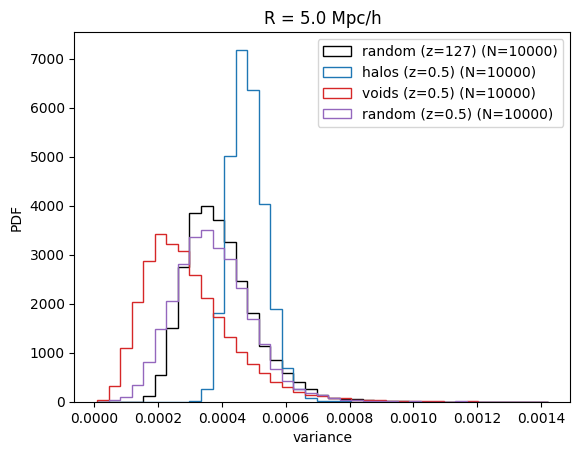

random (z=127)   kept  10000
halos (z=0.5)    kept  10000
voids (z=0.5)    kept  10000
random (z=0.5)   kept  10000


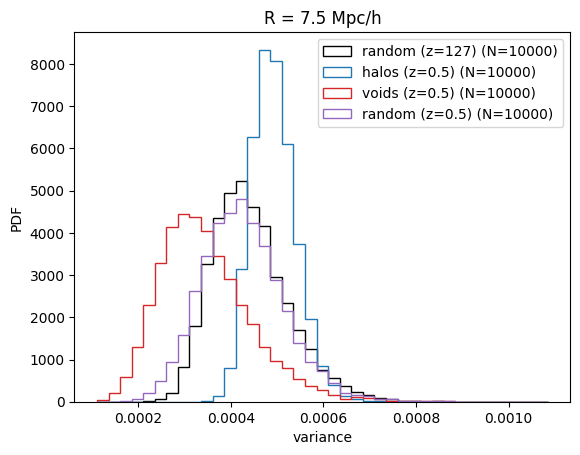

random (z=127)   kept  10000
halos (z=0.5)    kept  10000
voids (z=0.5)    kept  10000
random (z=0.5)   kept  10000


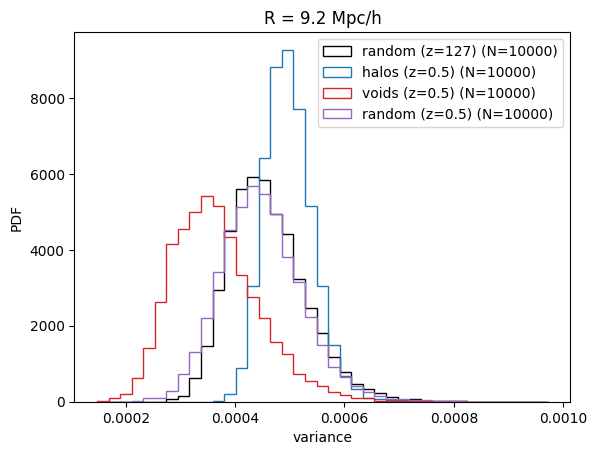

random (z=127)   kept  10000
halos (z=0.5)    kept  10000
voids (z=0.5)    kept  10000
random (z=0.5)   kept  10000


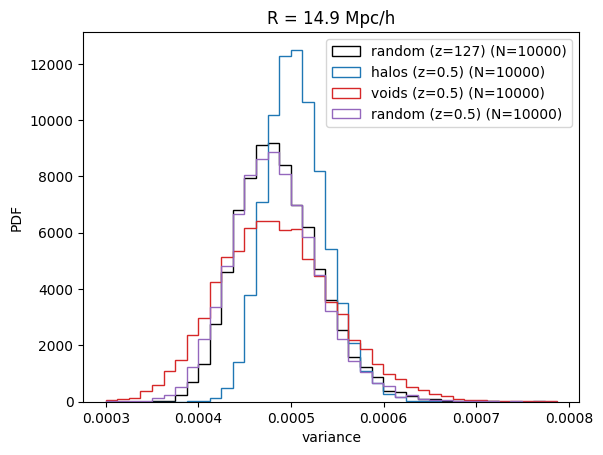

random (z=127)   kept  10000
halos (z=0.5)    kept  10000
voids (z=0.5)    kept  10000
random (z=0.5)   kept  10000


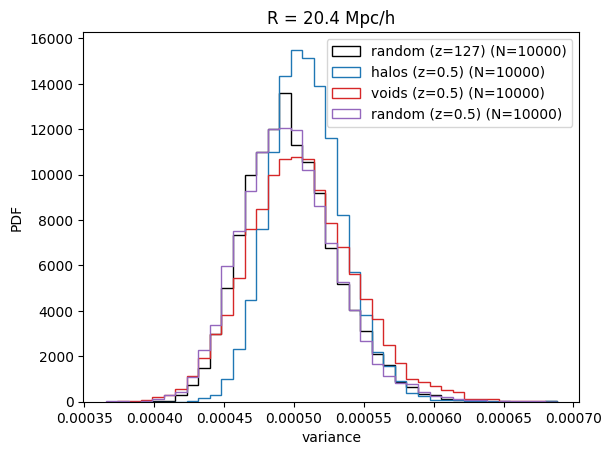

random (z=127)   kept  10000
halos (z=0.5)    kept  10000
voids (z=0.5)    kept  10000
random (z=0.5)   kept  10000


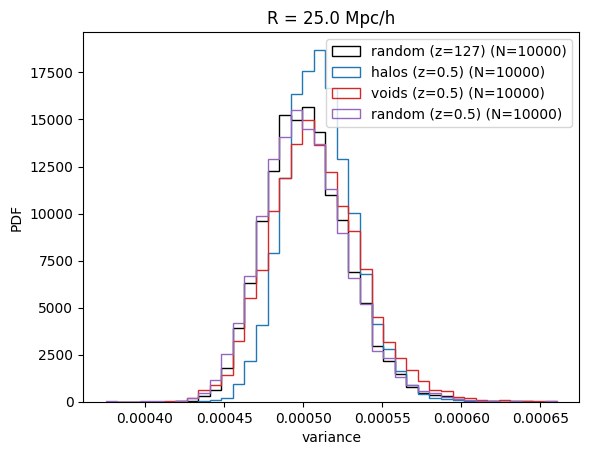

random (z=127)   kept  10000
halos (z=0.5)    kept  10000
voids (z=0.5)    kept  10000
random (z=0.5)   kept  10000


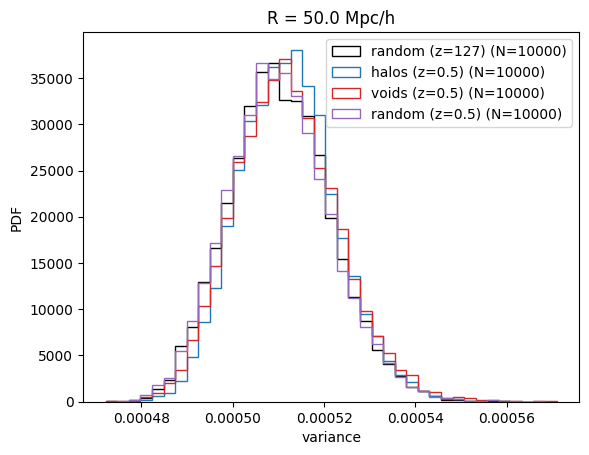

random (z=127)   kept  10000
halos (z=0.5)    kept  10000
voids (z=0.5)    kept  10000
random (z=0.5)   kept  10000


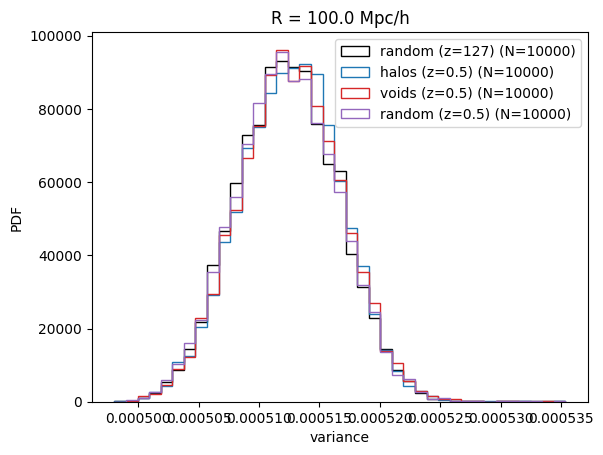

In [40]:
from scipy.stats import ks_2samp
import matplotlib.pyplot as plt
COL = {"random (z=127)": "k", "halos (z=0.5)": "C0", "voids (z=0.5)": "C3", "random (z=0.5)": "C4"}

def sel(name, k, nmin=0, unbiased=True):
    n, v = res[name]["n"][:, k], res[name]["var"][:, k]
    good = (n >= max(nmin, 2)) & np.isfinite(v) & (v > 0)
    out = v[good] * n[good] / (n[good] - 1) if unbiased else v[good]
    return out, n[good]

def compare(R_target_kpc, nmin=0, bins=40, unbiased=True):
    k = np.argmin(np.abs(RADII - R_target_kpc))
    data = {}
    for name in COL:
        data[name], n = sel(name, k, nmin, unbiased)
        med = np.median(data[name]) if len(data[name]) else np.nan
        print(f"{name:16s} kept {len(data[name]):6d}")
    #for name in ["halos (z=0.5)", "voids (z=0.5)"]:
        #for base in ["random (z=127)", "random (z=0.5)"]:
            #if len(data[name]) and len(data[base]):
                #print(f"  KS {name} vs {base}: p = {ks_2samp(data[base], data[name]).pvalue:.2e}")
    ok = [d for d in data.values() if len(d)]
    edges = np.linspace(min(d.min() for d in ok), max(d.max() for d in ok), bins)
    plt.figure()
    for name, d in data.items():
        if len(d): plt.hist(d, bins=edges, density=True, histtype="step", color=COL[name], label=f"{name} (N={len(d)})")
    plt.xlabel("variance"); plt.ylabel("PDF"); plt.title(f"R = {RADII[k]/1e3:.1f} Mpc/h"); plt.legend(); plt.show()

TARGETS   = np.array([5e3, 7.5e3, 1e4, 1.5e4, 2e4, 2.5e4, 5e4, 1e5])
for R in TARGETS:
    compare(R)

In [ ]:

#attempt to plot - halos
radii = np.logspace(1, 5, 15)  
var_global = np.var(delta_L_p, dtype=np.float64)

for i in (1, 2, 3, 10, 20, 40, 50, 100, 200): 
    res = var_vs_radius_binned(fin_pos_sorted, delta_L_p, halo_centers[i], radii, box_size)
    plt.plot(radii, res["var"], "o-", label=f"halo {i}")
    plt.xscale("log")
    del res                      # free memory before the next halo

plt.xlabel("radius")
plt.ylabel("variance(halos)")
plt.legend()
plt.show()

#voids
#attempt to plot - halos

for i in (1, 2, 3, 10, 20, 40, 50, 100, 200): #at 6 halos basically
    res = var_vs_radius_binned(fin_pos_sorted, delta_L_p, void_centers[i], radii, box_size)
    plt.plot(radii, res["var"], "o-", label=f"void {i}")
    plt.xscale("log")
    del res                      # free memory before the next halo

plt.xlabel("radius")
plt.ylabel("variance(void)")
plt.legend()
plt.show()

#random points
rng = np.random.default_rng(42)          # seed for reproducibility
L = 1000000.0                               # kpc/h
centers = rng.uniform(0, L, size=(11, 3))

for i in (0, 1, 2, 3, 4, 5, 6, 7, 8, 9): #at 6 halos basically
    res = var_vs_radius_binned(fin_pos_sorted, delta_L_p, centers[i], radii, box_size)
    plt.plot(radii, res["var"], "o-", label=f"random point {i}")
    plt.xscale("log")
    del res                      # free memory before the next halo

plt.xlabel("radius")
plt.ylabel("variance(random)")
plt.legend()
plt.show()

In [ ]:
#USING KDTREE

import numpy as np
from scipy.spatial import cKDTree

def sphere_stats(tree, vals, L, queries, radii, batch=None, target_pairs=5_000_000):
    """Mean and variance of vals inside spheres of each radius around each query point."""
    radii = np.sort(np.asarray(radii, dtype=np.float64)); K = len(radii); Rmax = radii[-1]
    if Rmax >= L / 2:
        raise ValueError("radius must be < L/2")

    w = vals.astype(np.float64) - vals.mean()            # centred values, for numerical stability
    expected = len(vals) * (4/3) * np.pi * Rmax**3 / L**3 # avg points per sphere at Rmax
    if batch is None:
        batch = max(1, int(target_pairs / max(expected, 1.0)))   # keeps pairs per batch bounded

    Q = len(queries)
    n  = np.empty((Q, K)); c1 = np.empty((Q, K)); c2 = np.empty((Q, K))

    for a in range(0, Q, batch):
        q  = np.asarray(queries[a:a+batch], dtype=np.float64) % L
        m  = len(q)
        qt = cKDTree(q, boxsize=L)
        pr = tree.sparse_distance_matrix(qt, Rmax, output_type="ndarray")   # fields i, j, v

        shell = np.searchsorted(radii, pr["v"], side="left")      # smallest radius containing the point
        flat  = pr["j"].astype(np.int64) * (K + 1) + shell
        wi    = w[pr["i"]]
        size  = m * (K + 1)

        shp = (m, K + 1)
        n [a:a+m] = np.cumsum(np.bincount(flat, minlength=size).reshape(shp)[:, :K], axis=1)
        c1[a:a+m] = np.cumsum(np.bincount(flat, weights=wi,    minlength=size).reshape(shp)[:, :K], axis=1)
        c2[a:a+m] = np.cumsum(np.bincount(flat, weights=wi*wi, minlength=size).reshape(shp)[:, :K], axis=1)

    with np.errstate(invalid="ignore", divide="ignore"):
        mean = c1 / n + vals.mean()
        var  = c2 / n - (c1 / n) ** 2
    return dict(n=n, mean=mean, var=var, radii=radii)

L = box_size                                   # kpc/h, same units as everything below
centers = rng.uniform(0, L, size=(100_000, 3))
vals = delta_L_p   # field value at each random point

ok = np.isfinite(vals)                         # drop NaNs before building the tree
centers, vals = centers[ok], vals[ok]
tree = cKDTree(centers, boxsize=L, balanced_tree=False, compact_nodes=False)

radii = np.logspace(np.log10(5e4), np.log10(2e5), 20)      # 50 to 200 Mpc/h in kpc/h

rng = np.random.default_rng(42)
rand_centers = rng.uniform(0, L, size=(100_000, 3))   # fresh points, independent of the tree

res_rand = sphere_stats(tree, vals, L, rand_centers, radii)
res_halo = sphere_stats(tree, vals, L, np.asarray(halo_centers), radii)
res_void = sphere_stats(tree, vals, L, np.asarray(void_centers), radii)

R_target = 1e5                                   # kpc/h
k = np.argmin(np.abs(radii - R_target))
print("using R =", radii[k])

min_n = 30                                       # drop spheres with too few points for a stable variance
samples = {}
for name, res in [("random", res_rand), ("halo", res_halo), ("void", res_void)]:
    good = (res["n"][:, k] >= min_n) & np.isfinite(res["var"][:, k])
    samples[name] = res["var"][good, k]
    v = samples[name]
    print(f"{name:7s} N={len(v):7d}  median={np.median(v):.4g}  "
          f"mean={v.mean():.4g}  16-84%=({np.percentile(v,16):.4g}, {np.percentile(v,84):.4g})")


import matplotlib.pyplot as plt

allv = np.concatenate(list(samples.values()))
bins = np.logspace(np.log10(allv[allv>0].min()), np.log10(allv.max()), 60)   # shared bins

for name, v in samples.items():
    plt.hist(v, bins=bins, density=True, histtype="step", lw=2, label=f"{name} (N={len(v)})")
plt.xscale("log"); plt.xlabel(r"variance of $\delta$ in sphere"); plt.ylabel("PDF")
plt.title(f"R = {radii[k]/1e3:.0f} Mpc/h"); plt.legend(); plt.show()